# 03 — B-cell chromatin views (four tonsils)

Non-plasma B cells (plasma excluded; **2,635** cells on the H3K27ac set).
Main-paper **Figure 3**: Harmony-corrected spectral UMAPs for **H3K27ac** and
**H3K27me3**, colored by stage (**Naive** / **GC** / **Memory**), for:

- all tiles
- promoters (TSS −1 kb / +250 bp)
- **distal enhancers** (Stephanie MERs that do not overlap a promoter)

**Panels below are drawn from the frozen coordinate files** bundled as
`paper_results/H3K27ac_stage_umap_coordinates.npz` and
`paper_results/H3K27me3_stage_umap_coordinates.npz`, which match the manuscript
figures. Spectral embedding, Harmony, neighbors, and UMAP are intrinsically
stochastic: even with a fixed random seed, a full recompute can shift the
layout slightly. That is expected and does not indicate an error. An optional
regenerate snippet is included at the end (commented out) for transparency.

Plots are display-only (file writes commented out).


In [7]:
%matplotlib inline
import sys
import warnings
from pathlib import Path

warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", UserWarning)

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

PACKAGE = Path("/mnt/data1/divyanshu/treseq/tonsils/codes/treseq_paper")
if str(PACKAGE.parent) not in sys.path:
    sys.path.insert(0, str(PACKAGE.parent))

from treseq_paper import config
import importlib
importlib.reload(config)

sns.set_theme("talk", style="ticks")
sc.settings.verbosity = 1
plt.rcParams["figure.dpi"] = 120

PANELS = ["H3K27ac", "H3K27me3"]
VIEWS = list(config.STAGE_UMAP_VIEWS)
STAGE_ORDER = config.STAGE_ORDER
STAGE_PALETTE = config.STAGE_PALETTE
STAGE_SOURCE_MAP = config.STAGE_SOURCE_MAP
EXPECTED_N = config.BCELL_STAGE_N
EXPECTED_BINS = config.STAGE_UMAP_EXPECTED_N_BINS
NPZ_KEY = config.STAGE_UMAP_NPZ_KEYS

for path in config.STAGE_UMAP_NPZ.values():
    if not path.is_file():
        raise FileNotFoundError(path)


## Frozen UMAP coordinates (match the manuscript figure)


In [8]:
def load_stage_umap(modality: str):
    path = config.STAGE_UMAP_NPZ[modality]
    stored = np.load(path, allow_pickle=True)
    raw_stage = np.asarray(stored["stage"]).astype(str)
    stage = pd.Series(raw_stage).map(STAGE_SOURCE_MAP)
    if stage.isna().any():
        bad = sorted(set(raw_stage[stage.isna().to_numpy()]))
        raise RuntimeError(f"{modality}: unexpected stages {bad}")
    stage = pd.Categorical(stage, categories=STAGE_ORDER)
    if len(stage) != EXPECTED_N:
        raise RuntimeError(f"{modality}: {len(stage)} cells, expected {EXPECTED_N}")
    coordinates = {}
    n_bins = {}
    for view in VIEWS:
        key = NPZ_KEY[view]
        xy = np.asarray(stored[key], dtype=np.float32)
        if xy.shape != (EXPECTED_N, 2):
            raise RuntimeError(f"{modality} {view}: shape {xy.shape}")
        coordinates[view] = xy
        n_bins[view] = int(stored[f"n_bins_{key}"])
    if n_bins != EXPECTED_BINS[modality]:
        raise RuntimeError(f"{modality}: unexpected bin counts {n_bins}")
    counts = pd.Series(stage).value_counts().reindex(STAGE_ORDER).to_dict()
    print(
        f"loaded {path.name}: {EXPECTED_N} cells; stages {counts}; "
        f"bins {n_bins}"
    )
    return {"stage": stage, "coordinates": coordinates, "n_bins": n_bins}


panel_state = {modality: load_stage_umap(modality) for modality in PANELS}


loaded H3K27ac_stage_umap_coordinates.npz: 2635 cells; stages {'Naive': 586, 'GC': 1534, 'Memory': 515}; bins {'all tiles': 1618834, 'promoters': 31143, 'distal enhancers': 77350}
loaded H3K27me3_stage_umap_coordinates.npz: 2635 cells; stages {'Naive': 586, 'GC': 1534, 'Memory': 515}; bins {'all tiles': 260058, 'promoters': 15645, 'distal enhancers': 8030}


## Stage UMAPs (Naive / GC / Memory)


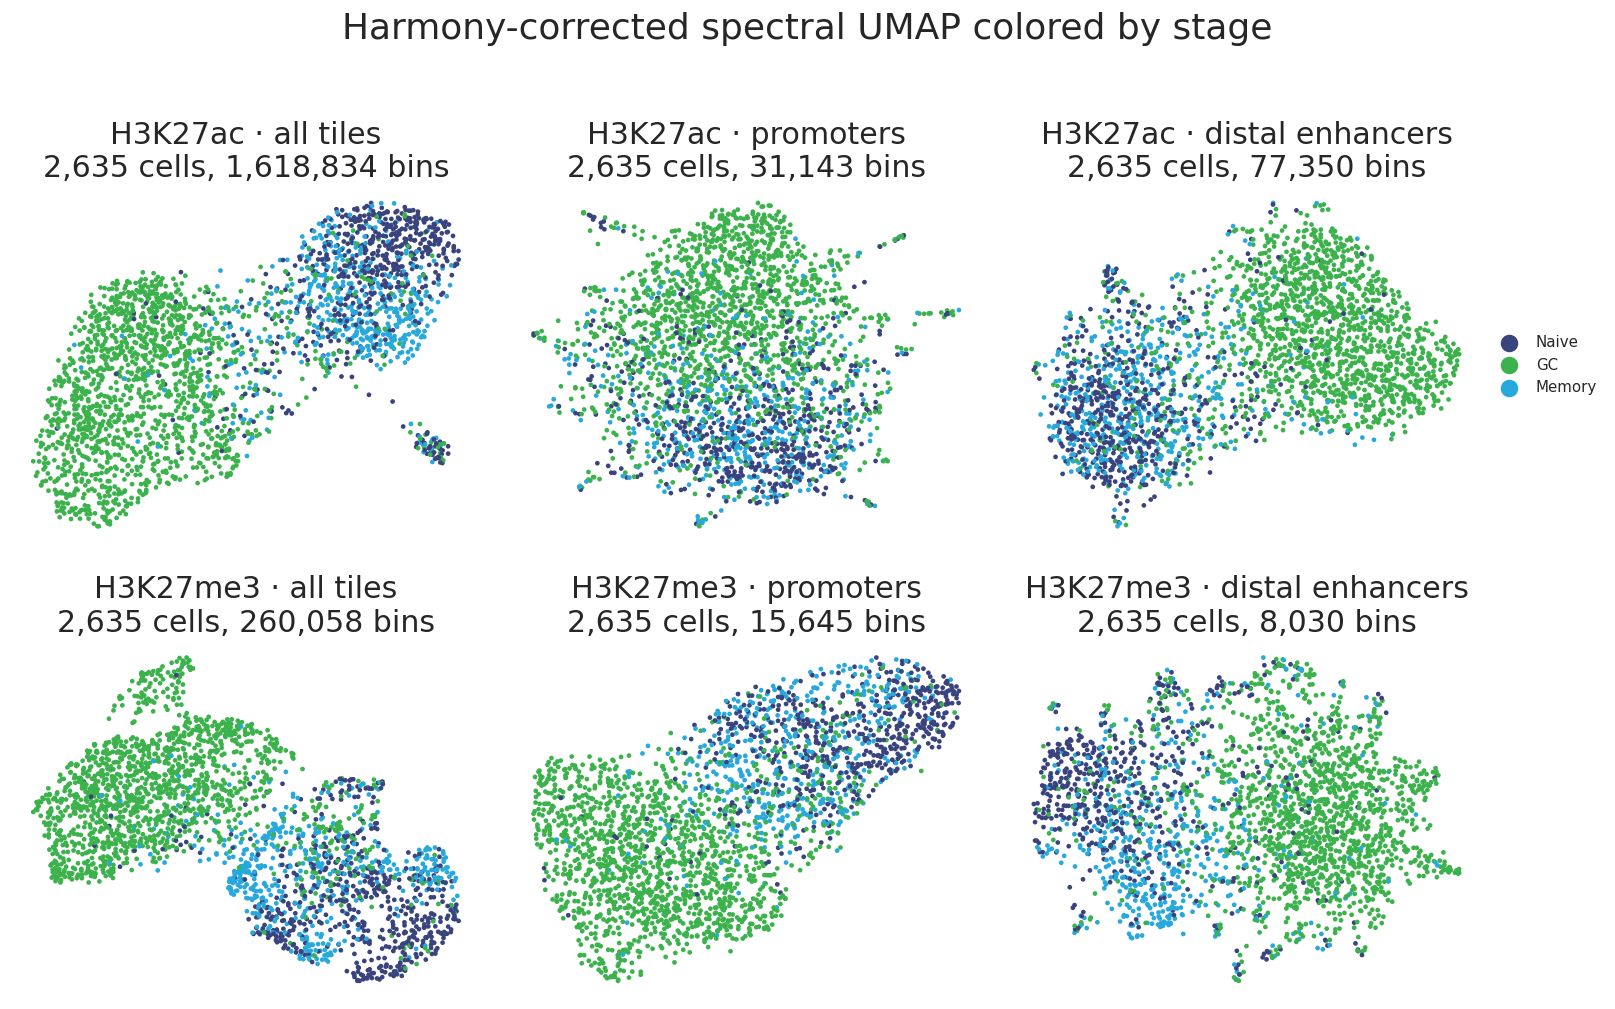

In [9]:
def draw_stage_umap(ax, xy, stage, title, legend):
    view = ad.AnnData(
        obs=pd.DataFrame({"stage": stage}),
        obsm={"X_umap": xy},
    )
    sc.pl.embedding(
        view,
        basis="umap",
        color="stage",
        palette=[STAGE_PALETTE[cat] for cat in STAGE_ORDER],
        title=title,
        ax=ax,
        show=False,
        frameon=False,
        legend_loc="right margin" if legend else "none",
        legend_fontsize=9,
        size=32,
    )


fig, axes = plt.subplots(len(PANELS), len(VIEWS), figsize=(4.6 * len(VIEWS), 4.2 * len(PANELS)))
for row, modality in enumerate(PANELS):
    state = panel_state[modality]
    for col, view in enumerate(VIEWS):
        heading = (
            f"{modality} · {view}\n"
            f"{EXPECTED_N:,} cells, {state['n_bins'][view]:,} bins"
        )
        draw_stage_umap(
            axes[row, col],
            state["coordinates"][view],
            state["stage"],
            heading,
            legend=(row == 0 and col == len(VIEWS) - 1),
        )
    axes[row, 0].set_ylabel(modality)

fig.suptitle("Harmony-corrected spectral UMAP colored by stage", y=1.01)
fig.tight_layout()
plt.show()
# fig.savefig("bcells_chromatin_stage_umap.pdf", bbox_inches="tight")  # disabled


## Optional: regenerate embeddings (commented out)

Uncomment only if you want to recompute spectral → Harmony → neighbors → UMAP
from `bcells.h5mu`. Layouts will be close to the frozen coordinates but are
**not guaranteed to match bit-for-bit**. Distal enhancers = Stephanie MERs
minus promoter overlap. Use the frozen files above for manuscript-identical
panels.


In [10]:
# import logging
# import os
# import time
#
# import hdf5plugin
# import muon as mu
# import snapatac2 as snap
# from pybedtools import BedTool
# from scipy import sparse
# from scipy.sparse.linalg import ArpackError
#
# os.environ["TQDM_DISABLE"] = "1"
# os.environ["HDF5_PLUGIN_PATH"] = hdf5plugin.PLUGIN_PATH
# os.environ["PATH"] = str(Path(sys.executable).resolve().parent) + os.pathsep + os.environ.get("PATH", "")
# logging.getLogger("harmonypy").setLevel(logging.ERROR)
#
# BCELLS = config.BCELLS
# STEPHANIE = config.STEPHANIE_MERS
# PROMOTERS_BED = config.PROMOTERS_BED
# CHROM_SIZES = config.CHROM_SIZES
# LABEL = config.CELLTYPE_KEY
# CELLTYPE_SOURCE = config.CELLTYPE_SOURCE_KEY
# B_ORDER = config.B_ORDER
# SAMPLE_ORDER = config.SAMPLE_ORDER
# N_COMPS = config.N_COMPS
# N_NEIGHBORS = config.N_NEIGHBORS
# MIN_DIST = config.MIN_DIST
# RANDOM_STATE = config.BCELL_RANDOM_STATE
# STORED_UP = config.STORED_PROMOTER_UPSTREAM
# STORED_DOWN = config.STORED_PROMOTER_DOWNSTREAM
# PROMOTER_UPSTREAM = config.PROMOTER_UPSTREAM
# PROMOTER_DOWNSTREAM = config.PROMOTER_DOWNSTREAM
# PANEL_OF = {"H3K27ac": "H3K27ac", "H3K27me3": "H3K27me3_ac"}
# EXPECTED_STAGE = {
#     "H3K27ac": {"Naive": 586, "GC": 1534, "Memory": 515},
#     "H3K27me3": {"Naive": 586, "GC": 1534, "Memory": 515},
# }
# REGEN_VIEWS = ["all tiles", "promoters", "distal enhancers"]
#
#
# def ensure_celltype(obs):
#     if LABEL in obs.columns:
#         return obs
#     if CELLTYPE_SOURCE not in obs.columns:
#         raise KeyError(f"missing {LABEL} / {CELLTYPE_SOURCE}")
#     return obs.rename(columns={CELLTYPE_SOURCE: LABEL})
#
#
# def ensure_stage(obs):
#     if "stage" in obs.columns:
#         mapped = obs["stage"].astype(str).replace(STAGE_SOURCE_MAP)
#         if set(mapped) - set(STAGE_ORDER):
#             # derive from cell type when stored stage is missing / unexpected
#             mapped = obs[LABEL].astype(str).map(config.STAGE_OF)
#         obs = obs.copy()
#         obs["stage"] = pd.Categorical(mapped, categories=STAGE_ORDER)
#         return obs
#     obs = obs.copy()
#     obs["stage"] = pd.Categorical(
#         obs[LABEL].astype(str).map(config.STAGE_OF), categories=STAGE_ORDER
#     )
#     return obs
#
#
# def bin_table(var_names):
#     names = pd.Index(var_names).astype(str)
#     span = names.str.split(":", n=1).str[1].str.split("-", n=1)
#     return pd.DataFrame(
#         {
#             "chrom": names.str.split(":", n=1).str[0].to_numpy(),
#             "start": span.str[0].astype(int).to_numpy(),
#             "end": span.str[1].astype(int).to_numpy(),
#         }
#     )
#
#
# def promoter_bed(upstream, downstream):
#     bed = pd.read_csv(
#         PROMOTERS_BED,
#         sep="\t",
#         header=None,
#         names=["chrom", "start", "end", "name", "score", "strand"],
#     )
#     width = STORED_UP + STORED_DOWN
#     if not np.all((bed["end"] - bed["start"]).to_numpy() == width):
#         raise RuntimeError(f"Promoter annotation intervals are not all {width} bp")
#     plus = bed["strand"].eq("+").to_numpy()
#     tss = np.where(plus, bed["start"] + STORED_UP, bed["end"] - STORED_UP)
#     start = np.where(plus, tss - upstream, tss - downstream).astype(int)
#     end = np.where(plus, tss + downstream, tss + upstream).astype(int)
#     sizes = pd.read_csv(CHROM_SIZES, sep="\t", header=None, names=["chrom", "size"])
#     size_of = dict(zip(sizes["chrom"], sizes["size"].astype(int)))
#     chrom_size = bed["chrom"].map(size_of).to_numpy()
#     start = np.clip(start, 0, chrom_size)
#     end = np.clip(end, 0, chrom_size)
#     keep = end > start
#     if not np.all(keep):
#         raise RuntimeError(f"{int((~keep).sum())} promoters were clipped to an empty interval")
#     return pd.DataFrame(
#         {
#             "chrom": bed["chrom"].to_numpy(),
#             "start": start,
#             "end": end,
#             "name": bed["name"].to_numpy(),
#             "strand": bed["strand"].to_numpy(),
#         }
#     )
#
#
# def overlap_mask(var_names, bed):
#     regions = bin_table(var_names)
#     regions["name"] = np.arange(len(regions))
#     bins = BedTool.from_dataframe(regions[["chrom", "start", "end", "name"]]).sort()
#     other = BedTool.from_dataframe(bed[["chrom", "start", "end"]]).sort()
#     hit = bins.intersect(other, u=True).to_dataframe(names=["chrom", "start", "end", "name"])
#     mask = np.zeros(len(regions), dtype=bool)
#     if len(hit):
#         mask[hit["name"].astype(int).to_numpy()] = True
#     return mask
#
#
# def nonzero_columns(X, mask):
#     counts = np.asarray(X.sum(axis=0)).ravel()
#     keep = mask & (counts > 0)
#     if int(keep.sum()) < 2:
#         raise RuntimeError("Fewer than 2 tiles with a count")
#     return keep
#
#
# def tile_subset(X, obs, var_names, keep):
#     return ad.AnnData(
#         X=X[:, keep].copy(),
#         obs=obs.copy(),
#         var=pd.DataFrame(index=pd.Index(np.asarray(var_names)[keep], name="tile")),
#     )
#
#
# def batch_correct(adata):
#     sc.external.pp.harmony_integrate(
#         adata, key="sample", basis="X_spectral", adjusted_basis="X_spectral_harmony"
#     )
#
#
# def fit_graph(adata, basis):
#     sc.pp.neighbors(adata, use_rep=basis, n_neighbors=N_NEIGHBORS)
#     sc.tl.umap(adata, min_dist=MIN_DIST, random_state=RANDOM_STATE)
#
#
# def embed_histone(adata):
#     for attempt in range(3):
#         try:
#             snap.tl.spectral(adata, features=None, n_comps=N_COMPS, distance_metric="cosine")
#             break
#         except ArpackError:
#             if attempt == 2:
#                 raise
#     batch_correct(adata)
#     fit_graph(adata, "X_spectral_harmony")
#     adata.uns["n_bins"] = int(adata.n_vars)
#     adata.uns["n_comps"] = int(adata.obsm["X_spectral"].shape[1])
#     return adata
#
#
# promoters = promoter_bed(PROMOTER_UPSTREAM, PROMOTER_DOWNSTREAM)
# enhancers = pd.read_csv(
#     STEPHANIE, sep="\t", header=None, names=["chrom", "start", "end", "name"]
# )[["chrom", "start", "end"]]
#
# mdata = mu.read_h5mu(BCELLS)
# loaded = {}
# for modality, key in PANEL_OF.items():
#     source = mdata.mod[key]
#     source.obs = ensure_stage(ensure_celltype(source.obs))
#     if source.n_obs != EXPECTED_N:
#         raise RuntimeError(f"{modality} has {source.n_obs} cells, expected {EXPECTED_N}")
#     for emb_key in ("X_spectral", "X_spectral_harmony", "X_umap"):
#         if emb_key not in source.obsm:
#             raise KeyError(f"{modality} is missing {emb_key}")
#     stages = source.obs["stage"].astype(str).value_counts().to_dict()
#     if stages != EXPECTED_STAGE[modality]:
#         raise RuntimeError(f"{modality} stages are {stages}")
#     reference = {
#         "X_spectral": np.asarray(source.obsm["X_spectral"], dtype=np.float32),
#     }
#     data = ad.AnnData(
#         X=sparse.csr_matrix(source.X).copy(),
#         obs=source.obs[[LABEL, "sample", "stage"]].copy(),
#         var=pd.DataFrame(index=pd.Index(source.var_names.astype(str), name="tile")),
#     )
#     loaded[modality] = {"data": data, "reference": reference}
#     print(f"{modality}: {data.n_obs} cells, {data.n_vars:,} tiles")
# del mdata
#
# panel_state_recomputed = {}
# for modality in PANELS:
#     data = loaded[modality]["data"]
#     reference = loaded[modality]["reference"]
#     print(f"{modality}: building views (recompute)", flush=True)
#     promoter = overlap_mask(data.var_names, promoters)
#     enhancer = overlap_mask(data.var_names, enhancers)
#     distal = enhancer & ~promoter
#     detected = {
#         "all tiles": nonzero_columns(data.X, np.ones(data.n_vars, dtype=bool)),
#         "promoters": nonzero_columns(data.X, promoter),
#         "distal enhancers": nonzero_columns(data.X, distal),
#     }
#     embeddings = {}
#     for view_name in REGEN_VIEWS:
#         keep = detected[view_name]
#         print(f"  {view_name}: {int(keep.sum()):,} tiles with a count", flush=True)
#         if view_name == "all tiles":
#             work = ad.AnnData(X=data.X.copy(), obs=data.obs.copy(), var=data.var.copy())
#             work.obsm["X_spectral"] = np.asarray(reference["X_spectral"], dtype=np.float32)
#             batch_correct(work)
#             fit_graph(work, "X_spectral_harmony")
#             work.uns["n_bins"] = int(work.n_vars)
#         else:
#             work = embed_histone(tile_subset(data.X, data.obs, data.var_names, keep))
#         embeddings[view_name] = ad.AnnData(
#             obs=work.obs[[LABEL, "stage", "sample"]].copy(),
#             obsm={"X_umap": np.asarray(work.obsm["X_umap"], dtype=np.float32)},
#             uns={"n_bins": int(work.uns["n_bins"])},
#         )
#         del work
#     panel_state_recomputed[modality] = embeddings
#
# fig, axes = plt.subplots(len(PANELS), len(REGEN_VIEWS), figsize=(4.6 * 3, 4.2 * 2))
# for row, modality in enumerate(PANELS):
#     for col, view in enumerate(REGEN_VIEWS):
#         adata = panel_state_recomputed[modality][view]
#         heading = f"{modality} · {view} (recomputed)\n{adata.n_obs:,} cells, {adata.uns['n_bins']:,} bins"
#         sc.pl.embedding(
#             adata,
#             basis="umap",
#             color="stage",
#             palette=[STAGE_PALETTE[cat] for cat in STAGE_ORDER],
#             title=heading,
#             ax=axes[row, col],
#             show=False,
#             frameon=False,
#             legend_loc="right margin" if (row == 0 and col == 2) else "none",
#             legend_fontsize=9,
#             size=32,
#         )
#     axes[row, 0].set_ylabel(modality)
# fig.suptitle("Recomputed Harmony UMAP by stage (may differ from frozen)", y=1.01)
# fig.tight_layout()
# plt.show()
